# SEN12MS — Sentinel-1 only LULC Semantic Segmentation (Colab / GPU)

Trains a segmentation model on the packed subset `sen12ms_subset.zip`
(15 IGBP classes, 8000/1500/2000 patches, scene-disjoint).

**Before running:** `Runtime → Change runtime type → GPU (T4)`.

**Pipeline**
1. Mount Drive, unzip the packed subset (float16 S1 + uint8 labels).
2. 3-channel input trick `[VV, VH, VV-VH]` + per-channel standardization.
3. Pretrained U-Net (ResNet-34) — swap to DeepLabV3+ for the comparison variant.
4. Class-weighted CrossEntropy + Dice, `ignore_index=255`, AMP.
5. Checkpoint best-by-mIoU to Drive (resume-safe).
6. Test metrics: OA, mIoU, per-class IoU/F1, confusion matrix, prediction grid.


## 1. Dependencies

In [2]:
!pip -q install segmentation-models-pytorch==0.3.4 albumentations==1.4.0
import torch, numpy as np, matplotlib
print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU")

torch 2.14.1+cu130 | CUDA: True | Tesla T4


## 2. Mount Drive & unzip the subset

Upload `sen12ms_subset.zip` to your Drive first (e.g. `MyDrive/sen12ms/`).
Set `ZIP_PATH` below to where you put it.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

import os, zipfile, time
ZIP_PATH = '/content/drive/MyDrive/sen12ms/sen12ms_subset.zip'  # <-- edit if needed
DATA_DIR = '/content/sen12ms_subset'                            # fast local disk
CKPT_DIR = '/content/drive/MyDrive/sen12ms/checkpoints'         # persists on Drive
os.makedirs(CKPT_DIR, exist_ok=True)

if not os.path.exists(os.path.join(DATA_DIR, 's1_train.npy')):
    t = time.time()
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)
    print('unzipped in %.0fs' % (time.time() - t))
print(sorted(os.listdir(DATA_DIR)))

Mounted at /content/drive
unzipped in 70s
['class_mapping.csv', 'lbl_test.npy', 'lbl_train.npy', 'lbl_val.npy', 'meta_test.csv', 'meta_train.csv', 'meta_val.csv', 's1_test.npy', 's1_train.npy', 's1_val.npy']


## 3. Config

In [4]:
import pandas as pd, numpy as np, torch

CFG = dict(
    data_dir   = DATA_DIR,
    ckpt_dir   = CKPT_DIR,
    arch       = 'unet',          # 'unet' or 'deeplabv3plus'
    encoder    = 'resnet34',      # 'resnet34' / 'resnet50'
    img_size   = 256,
    n_classes  = 15,
    ignore     = 255,
    batch      = 16,
    epochs     = 40,
    lr         = 1.5e-4,
    wd         = 1e-4,
    patience   = 10,              # early stopping on val mIoU
    dice_w     = 0.5,             # loss = CE + dice_w * Dice
    num_workers= 2,
    seed       = 42,
)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(CFG['seed']); np.random.seed(CFG['seed'])

cmap = pd.read_csv(os.path.join(DATA_DIR, 'class_mapping.csv'))
cmap = cmap[cmap.train_label != 255].sort_values('train_label')
CLASS_NAMES = cmap.igbp_name.tolist()
assert len(CLASS_NAMES) == CFG['n_classes']
for i, n in enumerate(CLASS_NAMES):
    print(i, n)

0 Evergreen Needleleaf Forest
1 Evergreen Broadleaf Forest
2 Deciduous Broadleaf Forest
3 Mixed Forest
4 Closed Shrublands
5 Open Shrublands
6 Woody Savannas
7 Savannas
8 Grasslands
9 Permanent Wetlands
10 Croplands
11 Urban/Built-up
12 Cropland/Natural Vegetation Mosaic
13 Barren
14 Water


## 4. Dataset

S1 arrays are dB backscatter. We build 3 channels `[VV, VH, VV-VH]` and
**standardize** each channel with statistics estimated from the training split
(SAR has no meaningful ImageNet stats, so we normalize to ~zero-mean; the
pretrained encoder still gives a better initialization).

In [5]:
import numpy as np, torch
from torch.utils.data import Dataset, DataLoader

def load_split(split):
    s1  = np.load(os.path.join(CFG['data_dir'], f's1_{split}.npy'),  mmap_mode='r')
    lbl = np.load(os.path.join(CFG['data_dir'], f'lbl_{split}.npy'), mmap_mode='r')
    return s1, lbl

# --- estimate per-channel mean/std from a sample of the training set ---
s1_tr, lbl_tr = load_split('train')
idx = np.random.default_rng(0).choice(len(s1_tr), size=min(500, len(s1_tr)), replace=False)
samp = np.asarray(s1_tr[np.sort(idx)]).astype(np.float32)   # (k,2,H,W)
vv, vh = samp[:, 0], samp[:, 1]
diff = vv - vh
CH_MEAN = np.array([vv.mean(), vh.mean(), diff.mean()], np.float32)
CH_STD  = np.array([vv.std(),  vh.std(),  diff.std()],  np.float32) + 1e-6
print('channel mean', CH_MEAN, '\nchannel std ', CH_STD)

class SEN12Dataset(Dataset):
    def __init__(self, split, augment=False):
        self.s1, self.lbl = load_split(split)
        self.augment = augment
    def __len__(self):
        return len(self.s1)
    def __getitem__(self, i):
        s1 = np.asarray(self.s1[i]).astype(np.float32)      # (2,H,W)
        vv, vh = s1[0], s1[1]
        x = np.stack([vv, vh, vv - vh], 0)                  # (3,H,W)
        x = (x - CH_MEAN[:, None, None]) / CH_STD[:, None, None]
        y = np.asarray(self.lbl[i]).astype(np.int64)        # (H,W), 255=ignore
        if self.augment:
            if np.random.rand() < 0.5: x, y = x[:, :, ::-1], y[:, ::-1]
            if np.random.rand() < 0.5: x, y = x[:, ::-1, :], y[::-1, :]
            k = np.random.randint(4)
            if k: x, y = np.rot90(x, k, (1, 2)), np.rot90(y, k, (0, 1))
        return torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy(np.ascontiguousarray(y))

train_ds = SEN12Dataset('train', augment=True)
val_ds   = SEN12Dataset('val')
test_ds  = SEN12Dataset('test')
train_dl = DataLoader(train_ds, CFG['batch'], shuffle=True,  num_workers=CFG['num_workers'], pin_memory=True, drop_last=True)
val_dl   = DataLoader(val_ds,   CFG['batch'], shuffle=False, num_workers=CFG['num_workers'], pin_memory=True)
test_dl  = DataLoader(test_ds,  CFG['batch'], shuffle=False, num_workers=CFG['num_workers'], pin_memory=True)
print('batches  train', len(train_dl), 'val', len(val_dl), 'test', len(test_dl))

channel mean [-11.662386 -18.33588    6.673501] 
channel std  [4.878919  5.373909  3.1323507]
batches  train 500 val 94 test 125


## 5. Class weights (imbalance) + sample preview

 0 Evergreen Needleleaf Forest        freq  4.902%  w 1.03
 1 Evergreen Broadleaf Forest         freq  6.124%  w 0.92
 2 Deciduous Broadleaf Forest         freq  7.023%  w 0.86
 3 Mixed Forest                       freq  6.355%  w 0.90
 4 Closed Shrublands                  freq  0.777%  w 2.58
 5 Open Shrublands                    freq  6.666%  w 0.88
 6 Woody Savannas                     freq  8.738%  w 0.77
 7 Savannas                           freq 11.681%  w 0.67
 8 Grasslands                         freq  9.812%  w 0.73
 9 Permanent Wetlands                 freq  3.275%  w 1.26
10 Croplands                          freq  8.083%  w 0.80
11 Urban/Built-up                     freq  7.519%  w 0.83
12 Cropland/Natural Vegetation Mosaic freq  4.465%  w 1.08
13 Barren                             freq  7.136%  w 0.85
14 Water                              freq  7.446%  w 0.83


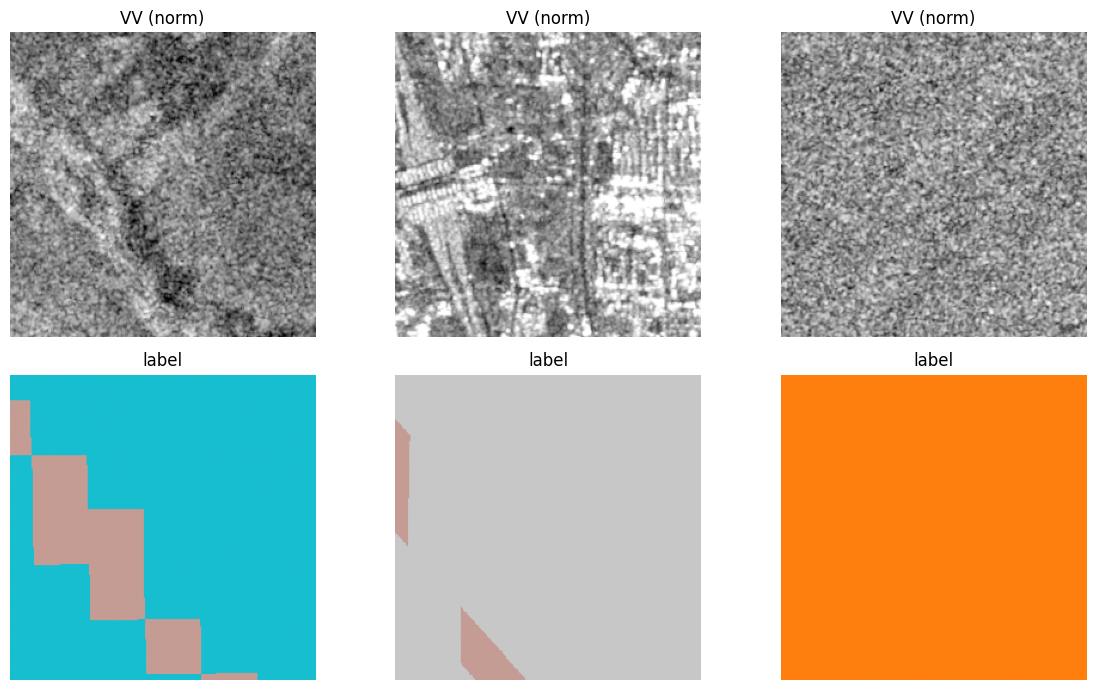

In [6]:
import matplotlib.pyplot as plt

# pixel frequency per class over the whole training split (chunked, mmap-safe)
counts = np.zeros(CFG['n_classes'], np.int64)
for s in range(0, len(lbl_tr), 1000):
    chunk = np.asarray(lbl_tr[s:s+1000])
    m = chunk != CFG['ignore']
    counts += np.bincount(chunk[m], minlength=CFG['n_classes'])
freq = counts / counts.sum()
weights = (1.0 / np.sqrt(freq + 1e-6))
weights = weights / weights.mean()                 # ~mean 1
CLASS_W = torch.tensor(weights, dtype=torch.float32, device=DEVICE)
for i, n in enumerate(CLASS_NAMES):
    print('%2d %-34s freq %6.3f%%  w %.2f' % (i, n, 100*freq[i], weights[i]))

# preview 3 samples (VV channel + label)
fig, ax = plt.subplots(2, 3, figsize=(12, 7))
for j in range(3):
    x, y = train_ds[j]
    ax[0, j].imshow(x[0], cmap='gray'); ax[0, j].set_title('VV (norm)'); ax[0, j].axis('off')
    ax[1, j].imshow(y, cmap='tab20', vmin=0, vmax=14); ax[1, j].set_title('label'); ax[1, j].axis('off')
plt.tight_layout(); plt.show()

## 6. Model, loss, metrics

In [7]:
import segmentation_models_pytorch as smp
import torch.nn as nn

def build_model():
    kw = dict(encoder_name=CFG['encoder'], encoder_weights='imagenet',
              in_channels=3, classes=CFG['n_classes'])
    return (smp.Unet(**kw) if CFG['arch'] == 'unet' else smp.DeepLabV3Plus(**kw))

model = build_model().to(DEVICE)

ce_loss = nn.CrossEntropyLoss(weight=CLASS_W, ignore_index=CFG['ignore'])
dice_loss = smp.losses.DiceLoss(mode='multiclass', ignore_index=CFG['ignore'])
def criterion(logits, y):
    return ce_loss(logits, y) + CFG['dice_w'] * dice_loss(logits, y)

optimizer = torch.optim.AdamW(model.parameters(), lr=CFG['lr'], weight_decay=CFG['wd'])
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG['epochs'])
scaler = torch.cuda.amp.GradScaler()

class ConfusionMeter:
    def __init__(self, n): self.n = n; self.cm = np.zeros((n, n), np.int64)
    def update(self, pred, tgt):
        k = (tgt >= 0) & (tgt < self.n)          # drops ignore(255)
        self.cm += np.bincount(self.n * tgt[k].astype(int) + pred[k],
                               minlength=self.n**2).reshape(self.n, self.n)
    def scores(self):
        cm = self.cm.astype(np.float64); d = np.diag(cm)
        iou = d / (cm.sum(1) + cm.sum(0) - d + 1e-9)
        f1  = 2 * d / (cm.sum(1) + cm.sum(0) + 1e-9)
        oa  = d.sum() / (cm.sum() + 1e-9)
        return oa, iou, f1

@torch.no_grad()
def evaluate(loader):
    model.eval(); meter = ConfusionMeter(CFG['n_classes']); loss_sum = 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.cuda.amp.autocast():
            logits = model(x); loss_sum += criterion(logits, y).item()
        pred = logits.argmax(1).cpu().numpy().ravel()
        meter.update(pred, y.cpu().numpy().ravel())
    oa, iou, f1 = meter.scores()
    return loss_sum / len(loader), oa, np.nanmean(iou), iou, f1, meter.cm

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1643: FutureWarning: `torch.jit.interface` is deprecated. Please use `torch.compile` instead.
  warnings.warn(


Downloading: "https://download.pytorch.org/models/resnet34-333f7ec4.pth" to /root/.cache/torch/hub/checkpoints/resnet34-333f7ec4.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 243MB/s]
/tmp/ipykernel_766/1228133180.py:18: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


## 7. Train (resume-safe, early stopping on val mIoU)

In [8]:
import json, time
BEST = os.path.join(CFG['ckpt_dir'], 'best_%s_%s_v2.pth' % (CFG['arch'], CFG['encoder']))
HIST = os.path.join(CFG['ckpt_dir'], 'history_%s_%s_v2.json' % (CFG['arch'], CFG['encoder']))

history = {'train_loss': [], 'val_loss': [], 'val_oa': [], 'val_miou': []}
start_epoch, best_miou, bad = 0, -1, 0
if os.path.exists(BEST):
    ck = torch.load(BEST, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ck['model']); optimizer.load_state_dict(ck['opt'])
    scheduler.load_state_dict(ck['sched']); start_epoch = ck['epoch'] + 1
    best_miou = ck['miou']; history = ck.get('history', history)
    print('resumed from epoch', start_epoch, 'best mIoU', round(best_miou, 4))

for epoch in range(start_epoch, CFG['epochs']):
    model.train(); run = 0; t = time.time()
    for x, y in train_dl:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        with torch.cuda.amp.autocast():
            loss = criterion(model(x), y)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer); scaler.update()
        run += loss.item()
    scheduler.step()
    vl, oa, miou, _, _, _ = evaluate(val_dl)
    tl = run / len(train_dl)
    history['train_loss'].append(tl); history['val_loss'].append(vl)
    history['val_oa'].append(oa);     history['val_miou'].append(miou)
    print('ep %2d  train %.3f  val %.3f  OA %.3f  mIoU %.3f  (%.0fs)'
          % (epoch, tl, vl, oa, miou, time.time() - t))

    if miou > best_miou:
        best_miou, bad = miou, 0
        torch.save({'model': model.state_dict(), 'opt': optimizer.state_dict(),
                    'sched': scheduler.state_dict(), 'epoch': epoch,
                    'miou': best_miou, 'cfg': CFG, 'history': history,
                    'ch_mean': CH_MEAN, 'ch_std': CH_STD}, BEST)
        print('   saved best -> %s' % BEST)
    else:
        bad += 1
        if bad >= CFG['patience']:
            print('early stop'); break
    json.dump(history, open(HIST, 'w'))
print('done. best val mIoU', round(best_miou, 4))

/tmp/ipykernel_766/1750806821.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_766/1228133180.py:38: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


ep  0  train 2.444  val 2.445  OA 0.273  mIoU 0.143  (85s)
   saved best -> /content/drive/MyDrive/sen12ms/checkpoints/best_unet_resnet34_v2.pth
ep  1  train 2.094  val 2.305  OA 0.334  mIoU 0.177  (86s)
   saved best -> /content/drive/MyDrive/sen12ms/checkpoints/best_unet_resnet34_v2.pth
ep  2  train 1.977  val 2.290  OA 0.288  mIoU 0.181  (89s)
   saved best -> /content/drive/MyDrive/sen12ms/checkpoints/best_unet_resnet34_v2.pth
ep  3  train 1.865  val 2.250  OA 0.348  mIoU 0.210  (89s)
   saved best -> /content/drive/MyDrive/sen12ms/checkpoints/best_unet_resnet34_v2.pth
ep  4  train 1.783  val 2.432  OA 0.334  mIoU 0.208  (90s)
ep  5  train 1.708  val 2.129  OA 0.364  mIoU 0.232  (89s)
   saved best -> /content/drive/MyDrive/sen12ms/checkpoints/best_unet_resnet34_v2.pth
ep  6  train 1.644  val 2.132  OA 0.414  mIoU 0.284  (91s)
   saved best -> /content/drive/MyDrive/sen12ms/checkpoints/best_unet_resnet34_v2.pth
ep  7  train 1.570  val 2.163  OA 0.411  mIoU 0.266  (91s)
ep  8  train

## 8. Training curves

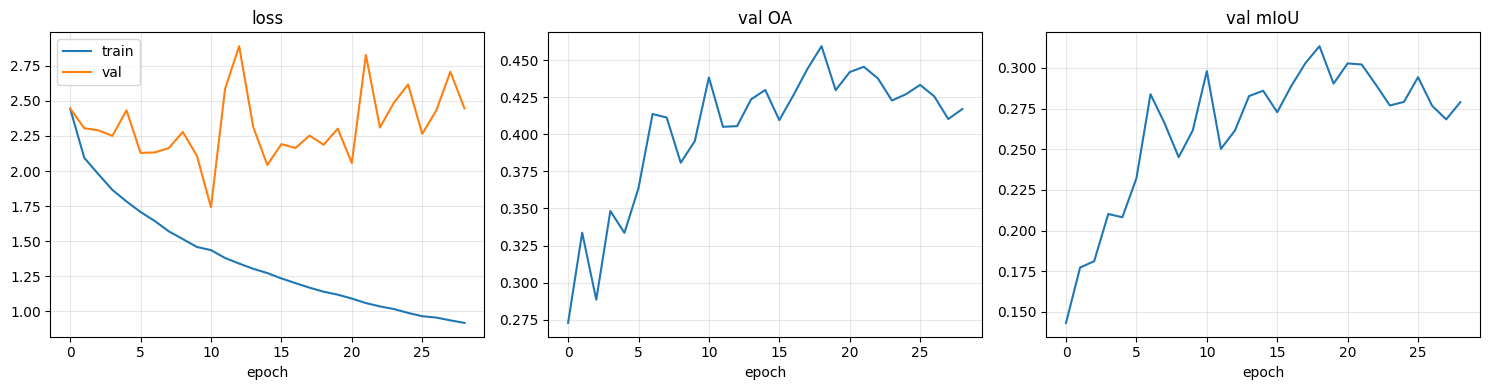

In [9]:
import matplotlib.pyplot as plt
h = history
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(h['train_loss'], label='train'); ax[0].plot(h['val_loss'], label='val')
ax[0].set_title('loss'); ax[0].legend()
ax[1].plot(h['val_oa']);   ax[1].set_title('val OA')
ax[2].plot(h['val_miou']); ax[2].set_title('val mIoU')
for a in ax: a.set_xlabel('epoch'); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(CFG['ckpt_dir'], 'curves.png'), dpi=120); plt.show()

## 9. Test-set evaluation (OA, mIoU, per-class IoU/F1, confusion matrix)

/tmp/ipykernel_766/1228133180.py:38: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


TEST  OA 0.4122   mIoU 0.2500

class                                  IoU      F1    test_px
Evergreen Needleleaf Forest          0.106   0.192    6531581
Evergreen Broadleaf Forest           0.722   0.838   11316103
Deciduous Broadleaf Forest           0.184   0.311   10115849
Mixed Forest                         0.179   0.304   10832984
Closed Shrublands                    0.000   0.000     286732
Open Shrublands                      0.229   0.372    9614544
Woody Savannas                       0.250   0.400   12960929
Savannas                             0.138   0.243   14221062
Grasslands                           0.181   0.307   14131680
Permanent Wetlands                   0.338   0.506    1992359
Croplands                            0.306   0.468   12822189
Urban/Built-up                       0.646   0.785   11884622
Cropland/Natural Vegetation Mosaic   0.057   0.108     862465
Barren                               0.213   0.351   12870991
Water                                0.

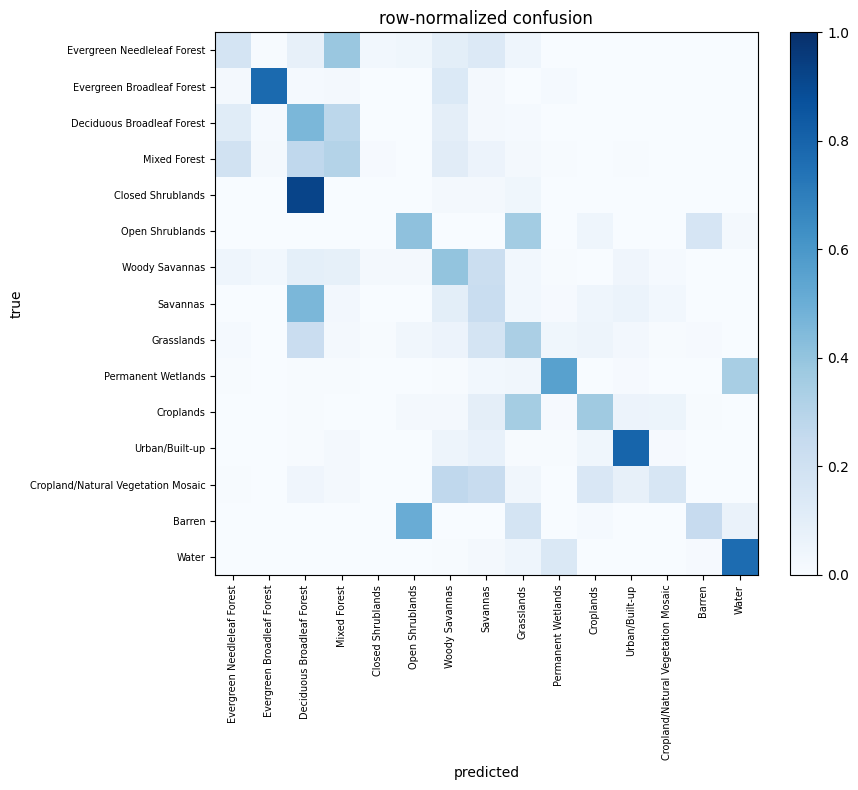


saved test_metrics.json


In [10]:
ck = torch.load(BEST, map_location=DEVICE, weights_only=False); model.load_state_dict(ck['model'])
tl, oa, miou, iou, f1, cm = evaluate(test_dl)
print('TEST  OA %.4f   mIoU %.4f\n' % (oa, miou))
print('%-34s %7s %7s %10s' % ('class', 'IoU', 'F1', 'test_px'))
support = cm.sum(1)
for i, n in enumerate(CLASS_NAMES):
    print('%-34s %7.3f %7.3f %10d' % (n, iou[i], f1[i], support[i]))

import matplotlib.pyplot as plt
cmn = cm / (cm.sum(1, keepdims=True) + 1e-9)
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(len(CLASS_NAMES))); ax.set_yticks(range(len(CLASS_NAMES)))
ax.set_xticklabels(CLASS_NAMES, rotation=90, fontsize=7); ax.set_yticklabels(CLASS_NAMES, fontsize=7)
ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title('row-normalized confusion')
plt.colorbar(im, fraction=0.046); plt.tight_layout()
plt.savefig(os.path.join(CFG['ckpt_dir'], 'confusion.png'), dpi=120); plt.show()

metrics = {'test_oa': float(oa), 'test_miou': float(miou),
           'per_class_iou': {CLASS_NAMES[i]: float(iou[i]) for i in range(len(CLASS_NAMES))},
           'per_class_f1':  {CLASS_NAMES[i]: float(f1[i])  for i in range(len(CLASS_NAMES))}}
json.dump(metrics, open(os.path.join(CFG['ckpt_dir'], 'test_metrics.json'), 'w'), indent=2)
print('\nsaved test_metrics.json')

## 10. Qualitative predictions

/tmp/ipykernel_766/1011159366.py:4: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.no_grad(), torch.cuda.amp.autocast():


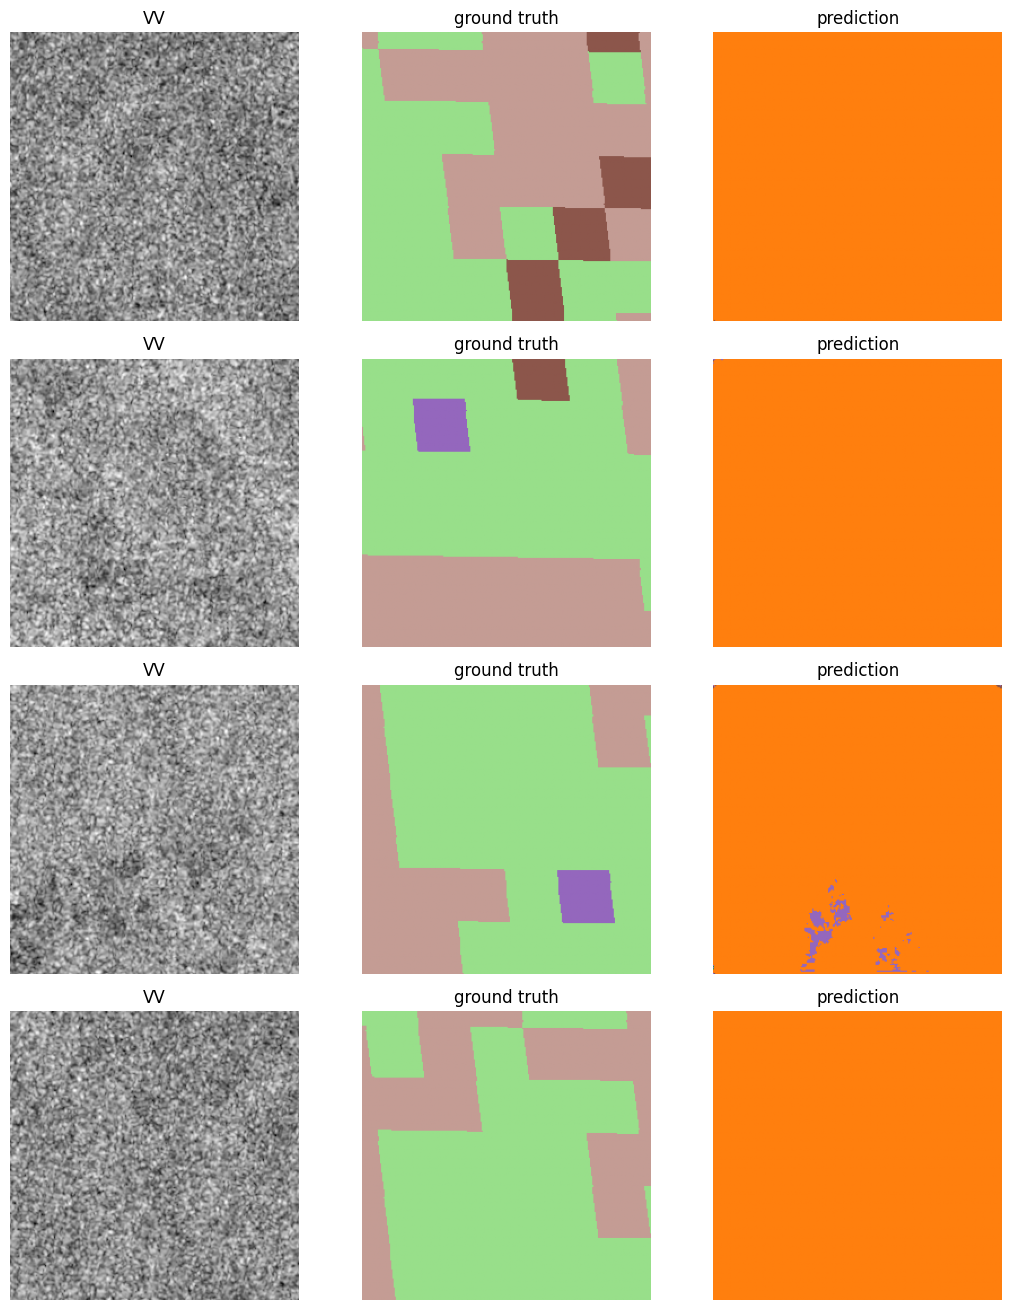

In [11]:
import matplotlib.pyplot as plt
model.eval()
x, y = next(iter(test_dl))
with torch.no_grad(), torch.cuda.amp.autocast():
    pred = model(x.to(DEVICE)).argmax(1).cpu().numpy()
rows = min(4, x.shape[0])
fig, ax = plt.subplots(rows, 3, figsize=(11, 3.3 * rows))
for r in range(rows):
    ax[r, 0].imshow(x[r, 0], cmap='gray');                        ax[r, 0].set_title('VV'); ax[r, 0].axis('off')
    ax[r, 1].imshow(y[r],    cmap='tab20', vmin=0, vmax=14);       ax[r, 1].set_title('ground truth'); ax[r, 1].axis('off')
    ax[r, 2].imshow(pred[r], cmap='tab20', vmin=0, vmax=14);       ax[r, 2].set_title('prediction'); ax[r, 2].axis('off')
plt.tight_layout(); plt.savefig(os.path.join(CFG['ckpt_dir'], 'predictions.png'), dpi=120); plt.show()

## 11. Next steps / report notes

- **Weights for the prototype:** `best_<arch>_<encoder>.pth` on Drive holds the
  model state **plus** `ch_mean`/`ch_std` — reuse the exact same standardization
  when you run live Sentinel-1 through the model.
- **Model-variant comparison (report bonus):** set `CFG['arch']='deeplabv3plus'`
  (or `encoder='resnet50'`), re-run; it saves under a different filename so both
  survive. Compare the two `test_metrics.json`.
- **If a class has very low test support** (shrublands, water-in-test), its IoU is
  noisy — report it with the pixel-support column and discuss in limitations.
- **Saved figures** (`curves.png`, `confusion.png`, `predictions.png`) and
  `test_metrics.json` go straight into the report.
